In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme()

In [2]:
from scipy.io import arff

data, meta = arff.loadarff("../data/Training Dataset.arff")
df = pd.DataFrame(data)
df = df.apply(lambda col: col.str.decode("utf-8") if col.dtype == object else col)
df = df.astype(int)
df.shape

(11055, 31)

In [3]:
df.head()

,having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,Favicon,...,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Result
0,-1,1,1,1,-1,-1,-1,-1,-1,1,...,1,1,-1,-1,-1,-1,1,1,-1,-1
1,1,1,1,1,1,-1,0,1,-1,1,...,1,1,-1,-1,0,-1,1,1,1,-1
2,1,0,1,1,1,-1,-1,-1,-1,1,...,1,1,1,-1,1,-1,1,0,-1,-1
3,1,0,1,1,1,-1,-1,-1,1,1,...,1,1,-1,-1,1,-1,1,-1,1,-1
4,1,0,-1,1,1,-1,1,1,-1,1,...,-1,1,-1,-1,0,-1,1,1,1,1


In [4]:
df.info()
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 11055 entries, 0 to 11054
Data columns (total 31 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   having_IP_Address            11055 non-null  int64
 1   URL_Length                   11055 non-null  int64
 2   Shortining_Service           11055 non-null  int64
 3   having_At_Symbol             11055 non-null  int64
 4   double_slash_redirecting     11055 non-null  int64
 5   Prefix_Suffix                11055 non-null  int64
 6   having_Sub_Domain            11055 non-null  int64
 7   SSLfinal_State               11055 non-null  int64
 8   Domain_registeration_length  11055 non-null  int64
 9   Favicon                      11055 non-null  int64
 10  port                         11055 non-null  int64
 11  HTTPS_token                  11055 non-null  int64
 12  Request_URL                  11055 non-null  int64
 13  URL_of_Anchor                11055 non-null  int64
 14  L

['having_IP_Address', 'URL_Length', 'Shortining_Service', 'having_At_Symbol', 'double_slash_redirecting', 'Prefix_Suffix', 'having_Sub_Domain', 'SSLfinal_State', 'Domain_registeration_length', 'Favicon', 'port', 'HTTPS_token', 'Request_URL', 'URL_of_Anchor', 'Links_in_tags', 'SFH', 'Submitting_to_email', 'Abnormal_URL', 'Redirect', 'on_mouseover', 'RightClick', 'popUpWidnow', 'Iframe', 'age_of_domain', 'DNSRecord', 'web_traffic', 'Page_Rank', 'Google_Index', 'Links_pointing_to_page', 'Statistical_report', 'Result']


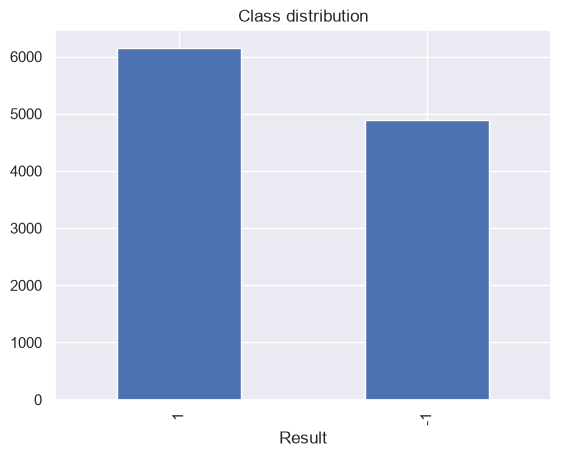

In [5]:
print(df.columns.tolist())
df["Result"].value_counts().plot(kind="bar")
plt.title("Class distribution")
plt.show()

## Initial Data Observations

**Dataset:** UCI Phishing Websites dataset (ARFF format)

- **Size:** 11,055 rows and 31 columns (30 features plus the target `Result`).
- **Feature type:** All features are discrete, taking values in {-1, 0, 1}, so no scaling is strictly required for tree-based models.
- **Missing values:** 0. No imputation is needed.
- **Target variable:** `Result` (1 = legitimate, -1 = phishing).
- **Class balance:** 6,157 legitimate (55.7%) and 4,898 phishing (44.3%). This is a moderate imbalance, not severe, but accuracy alone could still be misleading, so precision, recall and F1 will be reported.
- **Duplicates:** 5,206 duplicate rows (about 47.1% of the dataset).

### Implications
- The high duplicate count is a data quality concern. If identical rows appear in both the training and test sets, this causes **data leakage** and inflates the evaluation scores.
- Duplicates will be removed **before** the train/test split, leaving 5,849 unique rows.
- Class balance will be re-checked after deduplication, since it may change.
- This decision will be documented in the report as part of the data-quality and reliability discussion.

In [6]:
df["Result"].value_counts()

Result
 1    6157
-1    4898
Name: count, dtype: int64

In [7]:
print(df.nunique().sort_values())
print(df["Result"].value_counts(normalize=True))

having_IP_Address              2
Shortining_Service             2
having_At_Symbol               2
double_slash_redirecting       2
Prefix_Suffix                  2
port                           2
Favicon                        2
Domain_registeration_length    2
Request_URL                    2
HTTPS_token                    2
popUpWidnow                    2
RightClick                     2
on_mouseover                   2
Redirect                       2
Abnormal_URL                   2
Submitting_to_email            2
DNSRecord                      2
Page_Rank                      2
Google_Index                   2
Statistical_report             2
Result                         2
age_of_domain                  2
Iframe                         2
URL_Length                     3
SFH                            3
Links_in_tags                  3
URL_of_Anchor                  3
SSLfinal_State                 3
having_Sub_Domain              3
web_traffic                    3
Links_poin

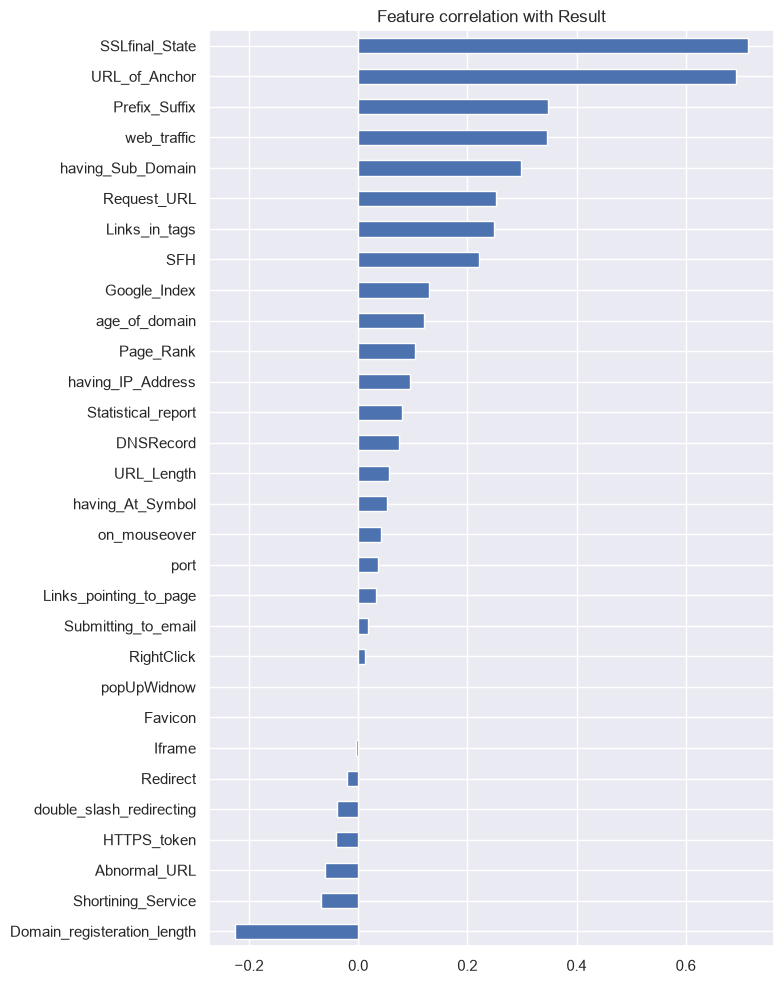

(having_Sub_Domain    0.298323
 web_traffic          0.346103
 Prefix_Suffix        0.348606
 URL_of_Anchor        0.692935
 SSLfinal_State       0.714741
 Name: Result, dtype: float64,
 Domain_registeration_length   -0.225789
 Shortining_Service            -0.067966
 Abnormal_URL                  -0.060488
 HTTPS_token                   -0.039854
 double_slash_redirecting      -0.038608
 Name: Result, dtype: float64)

In [8]:
corr = df.corr()["Result"].drop("Result").sort_values()
corr.plot(kind="barh", figsize=(8, 10))
plt.title("Feature correlation with Result")
plt.tight_layout()
plt.savefig("../reports/corr_with_target.png", dpi=150)
plt.show()
corr.tail(5), corr.head(5)

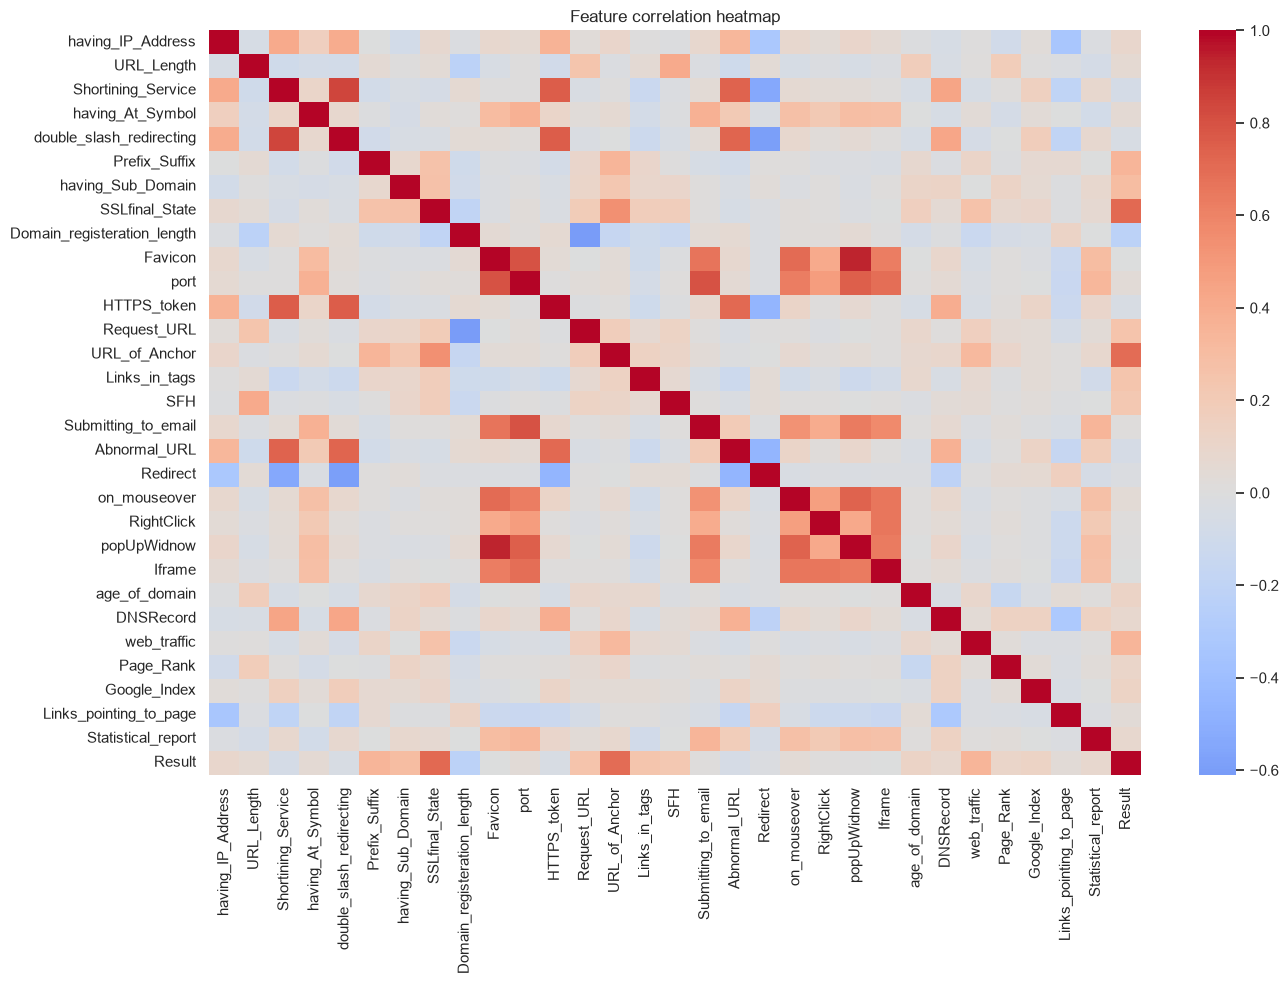

In [9]:
plt.figure(figsize=(14, 10))
sns.heatmap(df.corr(), cmap="coolwarm", center=0)
plt.title("Feature correlation heatmap")
plt.tight_layout()
plt.savefig("../reports/corr_heatmap.png", dpi=150)
plt.show()

## Correlation Analysis

### Correlation with the target (`Result`)

**Strongest positive correlations** (higher values are associated with legitimate sites):
- `SSLfinal_State` (about 0.71): the strongest single predictor.
- `URL_of_Anchor` (about 0.69): the second strongest, and close to `SSLfinal_State`.
- `Prefix_Suffix` (about 0.35) and `web_traffic` (about 0.35).
- `having_Sub_Domain` (about 0.30), followed by `Request_URL`, `Links_in_tags` and `SFH` (each about 0.22 to 0.25).

**Negative correlation:**
- `Domain_registeration_length` (about -0.23) is the only feature with a notable negative relationship. Its direction depends on how the dataset encodes the feature (see the features document).

**Very weak or no linear correlation (close to 0):**
- `popUpWidnow`, `Favicon`, `Iframe`, `RightClick`, `Submitting_to_email`, `Redirect`, `double_slash_redirecting` and `HTTPS_token`.

**Interpretation:** Most of the predictive signal appears to come from a small group of features, mainly `SSLfinal_State` and `URL_of_Anchor`. The two are clearly ahead of all the others. Pearson correlation only measures linear association, so a weakly correlated feature may still help a non-linear model such as a decision tree or random forest. Feature importance will be checked after modelling.

### Correlation between features (redundancy)

The top pairwise absolute correlations between features were:

| Feature 1 | Feature 2 | \|r\| |
|---|---|---|
| Favicon | popUpWidnow | 0.940 |
| Shortining_Service | double_slash_redirecting | 0.843 |
| Favicon | port | 0.804 |
| port | Submitting_to_email | 0.799 |
| double_slash_redirecting | HTTPS_token | 0.761 |
| Shortining_Service | HTTPS_token | 0.758 |
| port | popUpWidnow | 0.749 |
| Shortining_Service | Abnormal_URL | 0.739 |
| on_mouseover | popUpWidnow | 0.734 |
| double_slash_redirecting | Abnormal_URL | 0.724 |

Two clusters of redundant features stand out:
- **URL structure:** `Shortining_Service`, `double_slash_redirecting`, `HTTPS_token` and `Abnormal_URL`.
- **Page behaviour:** `Favicon`, `popUpWidnow`, `port`, `Submitting_to_email` and `on_mouseover`.

### Implications for modelling
- Multicollinearity can make **Logistic Regression** coefficients unstable and hard to interpret. Regularisation will be used, and results will be compared with tree-based models, which cope better with redundancy.
- Many of the redundant features also have weak correlation with the target, so they are candidates for removal in a feature-selection experiment. This will be tested rather than assumed.
- Features were not dropped at the EDA stage. The decision will be based on model performance.

In [10]:
dups = df.duplicated().sum()
print(f"Duplicates: {dups} ({dups / len(df):.1%} of rows)")

Duplicates: 5206 (47.1% of rows)


In [11]:
corr_matrix = df.drop(columns="Result").corr().abs()
pairs = (corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
         .stack().sort_values(ascending=False))
pairs.head(10)

Favicon                   popUpWidnow                 0.939633
Shortining_Service        double_slash_redirecting    0.842796
Favicon                   port                        0.803834
port                      Submitting_to_email         0.799088
double_slash_redirecting  HTTPS_token                 0.760799
Shortining_Service        HTTPS_token                 0.757838
port                      popUpWidnow                 0.748517
Shortining_Service        Abnormal_URL                0.739290
on_mouseover              popUpWidnow                 0.733629
double_slash_redirecting  Abnormal_URL                0.723724
dtype: float64